In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy
from tvb.simulator.lab import *

# Simulate with the Jansen and Rit model. 

In [JansenRit_1995] the extrinsic input p(t) of each column is noise spread
uniformly between $p_{min}$ = 120 and $p_{max}$ = 320 pulses/s. Two choices
keep this simulation inside that range (TVB time is in ms, so rates are in
ms$^{-1}$, e.g. `p_min = 0.12`):

- **Mean input.** Every region receives the constant drive `mu = p_min`. The
  connectome adds up to $p_{max} - p_{min}$ on top of it: the weights are
  normalised so that the largest in-strength is 1, and the coupling gain is set
  to $(p_{max} - p_{min}) / c_{max}$, where $c_{max}$ is the maximum of the
  `SigmoidalJansenRit` sigmoid, i.e. the maximum firing rate. With the raw
  weights and `a = 10`, the network input can reach about 3550 pulses/s, more
  than ten times the upper end of Jansen & Rit's range.
- **Fluctuations.** p(t) enters the equation of `y4` with gain $A\,a$, so the
  white noise is added there. Its dispersion is chosen so that, in units of
  the input, the noise amplitude is $(p_{max} - p_{min})/2$.

`v0 = 6` mV is the sigmoid threshold used by Jansen & Rit and matches the
`SigmoidalJansenRit` midpoint. The quantity plotted is $y_1 - y_2$, the
mean membrane potential of the pyramidal population, which is the model's EEG-like
output.

2026-11-26 19:32:09,664 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


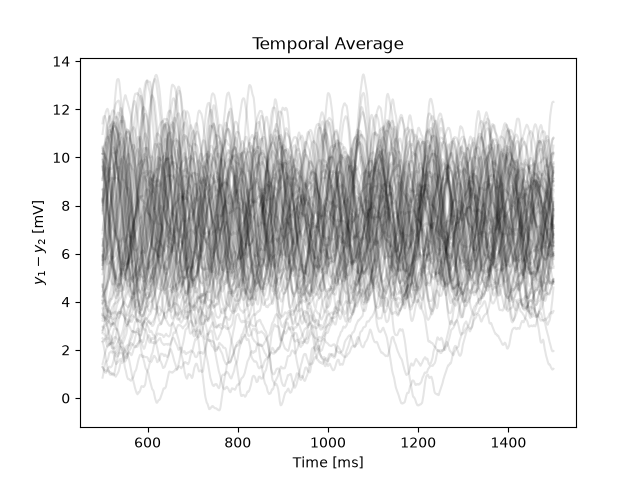

In [2]:
jrm = models.JansenRit(v0=numpy.array([6.]))
jrm.mu = jrm.p_min.copy()                      # mean input: 120 pulses/s

conn = connectivity.Connectivity.from_file()
conn.weights = conn.weights / conn.weights.sum(axis=1).max()   # largest in-strength = 1

cpl = coupling.SigmoidalJansenRit()
cpl.a = (jrm.p_max - jrm.p_min) / cpl.cmax      # network adds at most p_max - p_min

phi_n_scaling = (jrm.a * jrm.A * (jrm.p_max-jrm.p_min) * 0.5 )**2 / 2.
sigma         = numpy.zeros(6) 
sigma[4]      = phi_n_scaling.item()   # p(t) enters the y4 equation

# the other aspects of the simulator are standard
sim = simulator.Simulator(
    model=jrm,
    connectivity=conn,
    coupling=cpl,
    integrator=integrators.HeunStochastic(dt=2 ** -4, noise=noise.Additive(nsig=sigma)),
    monitors=(monitors.TemporalAverage(period=2 ** -2),),
    simulation_length=1.5e3,
).configure()

# run it; the random initial state is far from rest, so the sigmoid's exp()
# overflows for the first few ms and then saturates correctly at 0
with numpy.errstate(over="ignore"):
    (time, data), = sim.run()

# visualize time series
plt.figure()
# the first few hundred ms are a transient from the random initial conditions
keep = time >= 500.
plt.plot(time[keep], data[keep, 1, :, 0] - data[keep, 2, :, 0], 'k', alpha=0.1)  # y1 - y2
plt.xlabel('Time [ms]')
plt.ylabel('$y_1 - y_2$ [mV]')
plt.title("Temporal Average")
plt.show()